ANALYSE DU SOMMEIL - DATAFIT
Nuit : 1
Début : 2026-10-11 20:57:00
Fin : 2026-10-12 04:47:00

--- INDICATEURS ---
Durée enregistrée : 470 minutes
Durée de sommeil estimée : 350 minutes
Temps d'éveil estimé : 120 minutes
Efficacité estimée : 74.5 %

Fréquence cardiaque moyenne : 66.0 BPM
FC minimale : 52.3 BPM
FC maximale : 80.8 BPM
Mouvement moyen : 0.423
Agitation : 22.6 %

--- PHASES ESTIMÉES ---
Éveil : 120 minutes
Sommeil léger : 314 minutes
Sommeil profond : 35 minutes
Sommeil REM : 1 minutes

--- CONCLUSION ---
Type de sommeil estimé : Court

--- HORAIRES DES PHASES ---


,debut,fin,phase,duree_min
0,2026-10-11 20:57:00,2026-10-11 21:33:00,Eveil,36
1,2026-10-11 21:33:00,2026-10-11 21:44:00,Leger,11
2,2026-10-11 21:44:00,2026-10-11 21:45:00,Eveil,1
3,2026-10-11 21:45:00,2026-10-11 22:03:00,Leger,18
4,2026-10-11 22:03:00,2026-10-11 22:12:00,Profond,9
5,2026-10-11 22:12:00,2026-10-11 22:17:00,Leger,5
6,2026-10-11 22:17:00,2026-10-11 22:24:00,Profond,7
7,2026-10-11 22:24:00,2026-10-11 22:29:00,Leger,5
8,2026-10-11 22:29:00,2026-10-11 22:40:00,Eveil,11
9,2026-10-11 22:40:00,2026-10-11 23:07:00,Leger,27


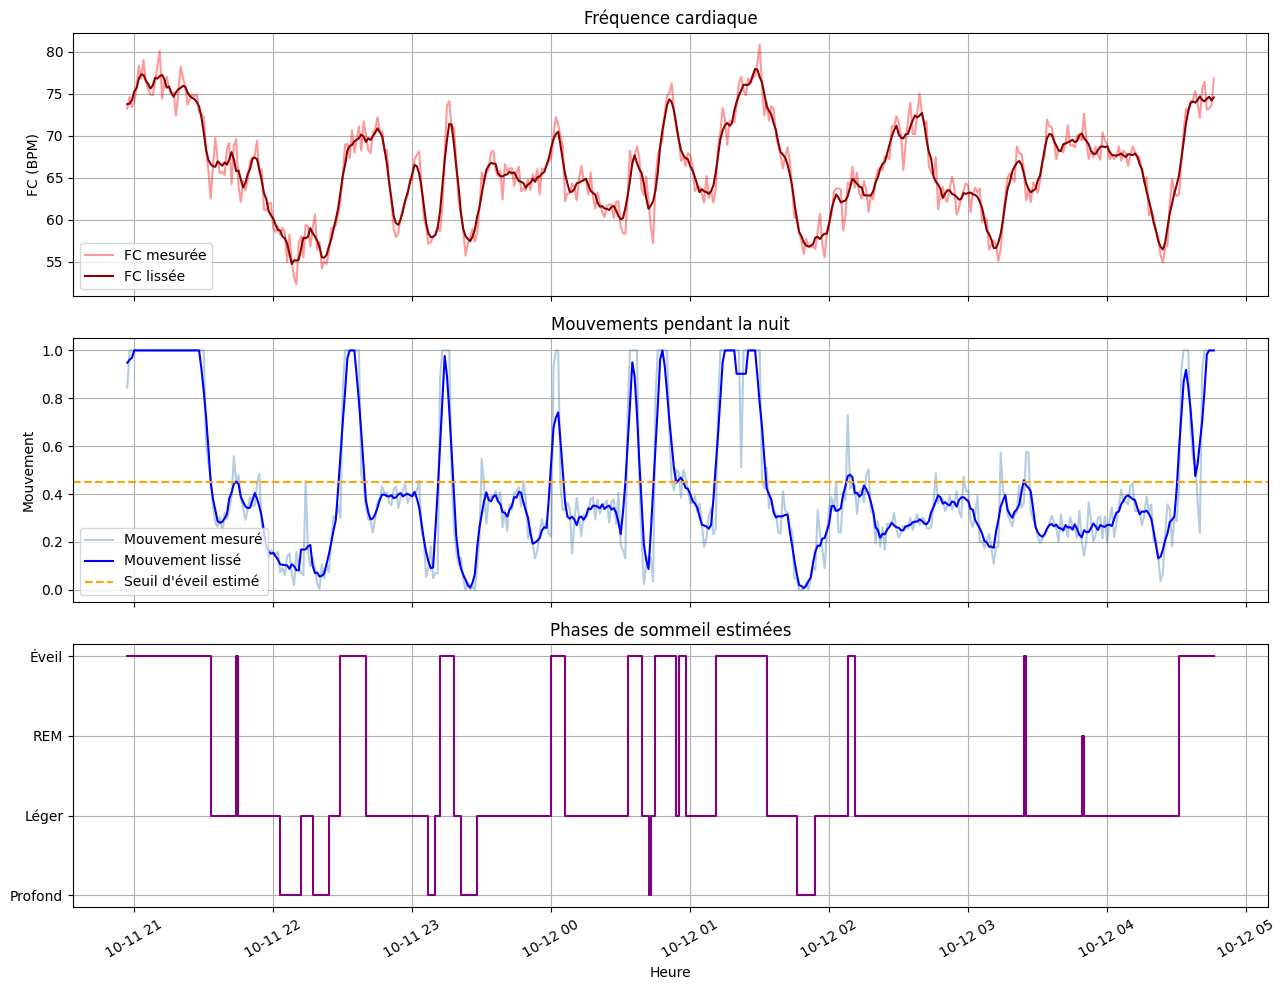

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def analyser_nuit(fichier="sommeil_mesures.csv", id_nuit=1):

    
    df = pd.read_csv(fichier)
    df["date_heure"] = pd.to_datetime(df["date_heure"])

   
    nuit = df[df["id_nuit"] == id_nuit].copy()
    nuit = nuit.sort_values("date_heure").reset_index(drop=True)

    if nuit.empty:
        print("Cette nuit n'existe pas dans le fichier.")
        return None, None

    
    duree_totale = len(nuit)

    fc_moyenne = nuit["fc_bpm"].mean()
    fc_min = nuit["fc_bpm"].min()
    fc_max = nuit["fc_bpm"].max()

    mouvement_moyen = nuit["mouvement"].mean()

    # 4. Lissage des données sur 5 minutes
    nuit["fc_lissee"] = nuit["fc_bpm"].rolling(
        window=5, center=True, min_periods=1
    ).mean()

    nuit["mouvement_lisse"] = nuit["mouvement"].rolling(
        window=5, center=True, min_periods=1
    ).mean()

    fc_reference = nuit["fc_lissee"].median()

    
    def classifier_phase(ligne):

        fc = ligne["fc_lissee"]
        mouvement = ligne["mouvement_lisse"]

        if mouvement >= 0.45:
            return "Eveil"

        elif mouvement < 0.12 and fc <= fc_reference - 4:
            return "Profond"

        elif mouvement < 0.22 and fc >= fc_reference + 2:
            return "REM"

        else:
            return "Leger"

    nuit["phase_estimee"] = nuit.apply(classifier_phase, axis=1)

    # 6. Durées estimées
    nb_eveil = (nuit["phase_estimee"] == "Eveil").sum()
    nb_leger = (nuit["phase_estimee"] == "Leger").sum()
    nb_profond = (nuit["phase_estimee"] == "Profond").sum()
    nb_rem = (nuit["phase_estimee"] == "REM").sum()

    duree_sommeil = nb_leger + nb_profond + nb_rem

    efficacite = duree_sommeil / duree_totale * 100

    agitation = (nuit["mouvement"] >= 0.5).mean() * 100

    
    if duree_sommeil < 360:
        type_sommeil = "Court"

    elif agitation >= 15 or efficacite < 85:
        type_sommeil = "Agite"

    elif duree_sommeil >= 420 and efficacite >= 90:
        type_sommeil = "Bon"

    else:
        type_sommeil = "Normal"

    
    nuit["groupe"] = (
        nuit["phase_estimee"] != nuit["phase_estimee"].shift()
    ).cumsum()

    periodes = nuit.groupby("groupe").agg(
        debut=("date_heure", "first"),
        derniere_mesure=("date_heure", "last"),
        phase=("phase_estimee", "first"),
        duree_min=("date_heure", "count")
    ).reset_index(drop=True)

    periodes["fin"] = (
        periodes["derniere_mesure"] + pd.Timedelta(minutes=1)
    )

    periodes = periodes[
        ["debut", "fin", "phase", "duree_min"]
    ]

    
    print("=" * 45)
    print("ANALYSE DU SOMMEIL - DATAFIT")
    print("=" * 45)

    print("Nuit :", id_nuit)
    print("Début :", nuit["date_heure"].iloc[0])
    print("Fin :", nuit["date_heure"].iloc[-1] +
          pd.Timedelta(minutes=1))

    print("\n--- INDICATEURS ---")
    print("Durée enregistrée :", duree_totale, "minutes")
    print("Durée de sommeil estimée :", duree_sommeil, "minutes")
    print("Temps d'éveil estimé :", nb_eveil, "minutes")
    print("Efficacité estimée :", round(efficacite, 1), "%")

    print("\nFréquence cardiaque moyenne :", round(fc_moyenne, 1), "BPM")
    print("FC minimale :", round(fc_min, 1), "BPM")
    print("FC maximale :", round(fc_max, 1), "BPM")
    print("Mouvement moyen :", round(mouvement_moyen, 3))
    print("Agitation :", round(agitation, 1), "%")

    print("\n--- PHASES ESTIMÉES ---")
    print("Éveil :", nb_eveil, "minutes")
    print("Sommeil léger :", nb_leger, "minutes")
    print("Sommeil profond :", nb_profond, "minutes")
    print("Sommeil REM :", nb_rem, "minutes")

    print("\n--- CONCLUSION ---")
    print("Type de sommeil estimé :", type_sommeil)

    print("\n--- HORAIRES DES PHASES ---")
    display(periodes)

    
    fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

    # Graphique FC
    axes[0].plot(
        nuit["date_heure"], nuit["fc_bpm"],
        color="red", alpha=0.4, label="FC mesurée"
    )
    axes[0].plot(
        nuit["date_heure"], nuit["fc_lissee"],
        color="darkred", label="FC lissée"
    )
    axes[0].set_ylabel("FC (BPM)")
    axes[0].set_title("Fréquence cardiaque")
    axes[0].legend()
    axes[0].grid(True)

   
    axes[1].plot(
        nuit["date_heure"], nuit["mouvement"],
        color="steelblue", alpha=0.4,
        label="Mouvement mesuré"
    )
    axes[1].plot(
        nuit["date_heure"], nuit["mouvement_lisse"],
        color="blue", label="Mouvement lissé"
    )
    axes[1].axhline(
        0.45, color="orange", linestyle="--",
        label="Seuil d'éveil estimé"
    )
    axes[1].set_ylabel("Mouvement")
    axes[1].set_title("Mouvements pendant la nuit")
    axes[1].legend()
    axes[1].grid(True)

    
    codes = {
        "Eveil": 3,
        "REM": 2,
        "Leger": 1,
        "Profond": 0
    }

    nuit["code_phase"] = nuit["phase_estimee"].map(codes)

    axes[2].step(
        nuit["date_heure"], nuit["code_phase"],
        where="post", color="purple"
    )

    axes[2].set_yticks([0, 1, 2, 3])
    axes[2].set_yticklabels(
        ["Profond", "Léger", "REM", "Éveil"]
    )
    axes[2].set_title("Phases de sommeil estimées")
    axes[2].set_xlabel("Heure")
    axes[2].grid(True)

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

    return nuit, periodes


# EXÉCUTION : analyser la nuit 1
nuit, periodes = analyser_nuit(
    fichier="sommeil_mesures.csv",
    id_nuit=1
)
